## Baseline Experiments Runner

- The algorithms are imported from baseline_updated.py
- The environment rules are imported from grid_world_env.py and blackjack_env.py. This notebook runs training, saves the experiment history and raw observed transitions, and produces plots.


In [1]:
from pathlib import Path
import csv
import json
import numpy as np
%pip install pandas
import pandas as pd
import matplotlib.pyplot as plt

from baseline import tomc, spmd
from grid_world_env import GridWorld
from blackjack_env import Blackjack

plt.style.use("ggplot")

Note: you may need to restart the kernel to use updated packages.


In [2]:
RUN_ENVIRONMENTS = ["blackjack"]   # or ["gridworld", "blackjack"]
N_ITERS = 100
ETA = 0.1
BIAS = 0.01
PI_MIN = None                   # None -> (1 - gamma) / n_actions
MAX_OBSERVATIONS = 200_000      # maximum per TOMC call
SEED = 42
OUTPUT_DIR = Path("results_notebook")

# Optional exploratory search; off by default because it may be expensive.
RUN_TUNING = False
ETA_GRID = [0.05, 0.1, 0.2]
BIAS_GRID = [0.005, 0.01, 0.02]
PI_MIN_MULTIPLIERS = [0.5, 1.0, 1.5]
TUNING_ITERS = 2
TUNING_MAX_OBSERVATIONS = 20_000  # per update, NOT strict total-budget control

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
def create_env(name):
    if name == "gridworld":
        env = GridWorld()
        return env, int(env.start)
    if name == "blackjack":
        env = Blackjack()
        return env, int(env.encode(8, 3))
    raise ValueError(f"Unknown environment: {name}")


def run_trial(name, eta=ETA, bias=BIAS, pi_min=PI_MIN,
              n_iters=N_ITERS, max_observations=MAX_OBSERVATIONS,
              seed=SEED, output_root=OUTPUT_DIR, save_transitions=True):
    env, s_0 = create_env(name)
    folder = Path(output_root) / name
    folder.mkdir(parents=True, exist_ok=True)
    observed = 0
    current_iteration = 0
    rows = []

    def log_transition(state, action, cost, next_state, done):
        nonlocal observed
        observed += 1
        if save_transitions:
            rows.append([current_iteration, observed, state, action,
                         float(cost), next_state, bool(done)])

    def estimate_Q(environment, pi_t, rng):
        nonlocal current_iteration
        current_iteration += 1
        return tomc(environment, pi_t, rng, bias=bias, pi_min=pi_min,
                    max_observations=max_observations, log_transition=log_transition)

    result = dict(environment=name, eta=eta, bias=bias, pi_min=pi_min,
                  seed=seed, requested_iterations=n_iters, status="complete")
    try:
        pi_t, V_s_0_arr, sample_arr = spmd(
            env, estimate_Q, lambda t: eta, s_0=s_0,
            n_iters=n_iters, seed=seed)
    except RuntimeError as exc:
        result.update(status="incomplete_coverage", error=str(exc),
                      total_observations=observed)
        (folder / "status.json").write_text(json.dumps(result, indent=2))
        if save_transitions:
            pd.DataFrame(rows, columns=["iteration", "observation", "state", "action",
                                        "cost", "next_state", "done"]).to_csv(folder / "transitions.csv", index=False)
        print(f"{name}: {exc} — observations saved, no final policy claimed")
        return result, None

    sample_arr = np.asarray(sample_arr, dtype=int)
    V_s_0_arr = np.asarray(V_s_0_arr, dtype=float)
    history = pd.DataFrame({
        "iteration": np.arange(1, len(V_s_0_arr) + 1),
        "estimated_V_before_update": V_s_0_arr,
        "running_average_V": np.cumsum(V_s_0_arr) / np.arange(1, len(V_s_0_arr) + 1),
        "cumulative_observations": sample_arr,
        "observations_this_iteration": np.diff(np.r_[0, sample_arr]),
    })
    history.to_csv(folder / "history.csv", index=False)
    pd.DataFrame(pi_t, columns=[f"action_{a}" for a in range(env.n_actions)]).rename_axis("state").to_csv(folder / "policy.csv")
    if save_transitions:
        pd.DataFrame(rows, columns=["iteration", "observation", "state", "action",
                                    "cost", "next_state", "done"]).to_csv(folder / "transitions.csv", index=False)
    result.update(total_observations=observed,
                  estimated_last_preupdate_value=float(V_s_0_arr[-1]),
                  final_policy_evaluated=False)
    (folder / "status.json").write_text(json.dumps(result, indent=2))
    print(f"{name}: {n_iters} completed updates, {observed:,} training observations")
    return result, history

In [4]:
training_results = {}
for name in RUN_ENVIRONMENTS:
    status, history = run_trial(name)
    training_results[name] = (status, history)

pd.DataFrame([item[0] for item in training_results.values()])

blackjack: 100 completed updates, 175,305 training observations


,environment,eta,bias,pi_min,seed,requested_iterations,status,total_observations,estimated_last_preupdate_value,final_policy_evaluated
0,blackjack,0.1,0.01,None,42,100,complete,175305,-0.611445,False


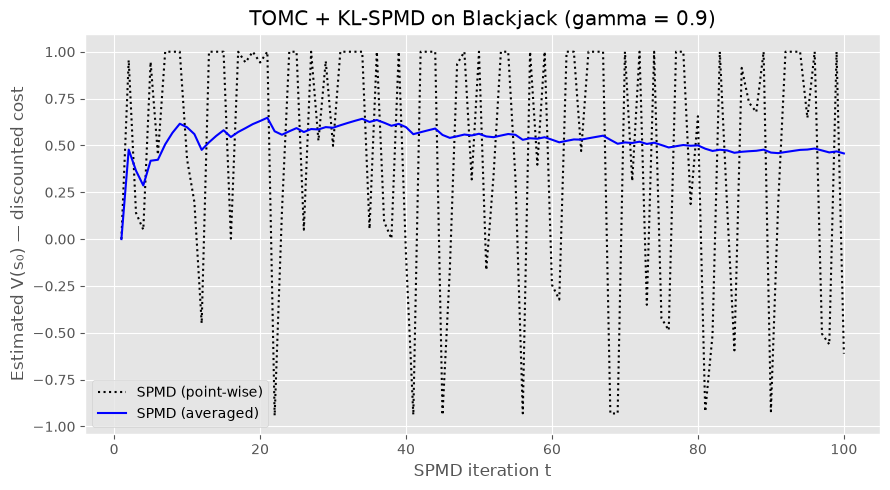

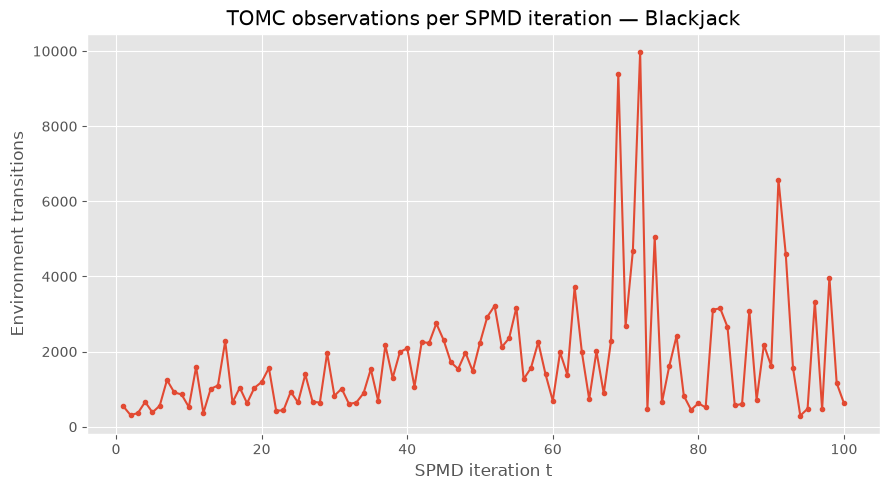

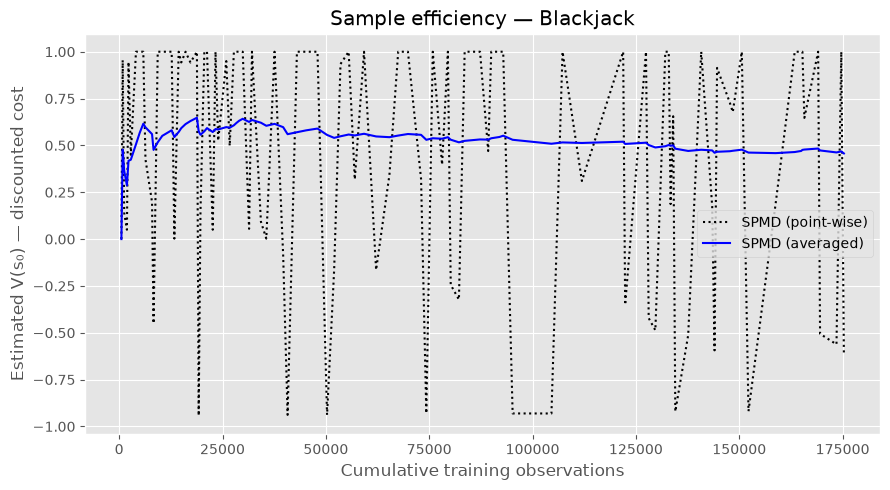

In [5]:
def plot_baseline(name, history, output_root=OUTPUT_DIR):
    if history is None or history.empty:
        print(f"{name}: no completed SPMD updates to plot")
        return

    folder = Path(output_root) / name
    x = history["iteration"]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(x, history["estimated_V_before_update"],
            label="SPMD (point-wise)", linestyle="dotted", color="black")
    ax.plot(x, history["running_average_V"],
            label="SPMD (averaged)", linestyle="solid", color="blue")
    ax.set(title=f"TOMC + KL-SPMD on {name.title()} (gamma = 0.9)",
           xlabel="SPMD iteration t", ylabel="Estimated V(s₀) — discounted cost")
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / "value_progression.png", dpi=180)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(x, history["observations_this_iteration"], marker="o", markersize=3)
    ax.set(title=f"TOMC observations per SPMD iteration — {name.title()}",
           xlabel="SPMD iteration t", ylabel="Environment transitions")
    fig.tight_layout()
    fig.savefig(folder / "observations_per_iteration.png", dpi=180)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(history["cumulative_observations"], history["estimated_V_before_update"],
            label="SPMD (point-wise)", linestyle="dotted", color="black")
    ax.plot(history["cumulative_observations"], history["running_average_V"],
            label="SPMD (averaged)", color="blue")
    ax.set(title=f"Sample efficiency — {name.title()}",
           xlabel="Cumulative training observations", ylabel="Estimated V(s₀) — discounted cost")
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / "sample_efficiency.png", dpi=180)
    plt.show()

for name, (status, history) in training_results.items():
    plot_baseline(name, history)

In [6]:
from itertools import product

tuning_rows = []
if RUN_TUNING:
    for name in RUN_ENVIRONMENTS:
        env, _ = create_env(name)
        base_pi_min = (1 - env.gamma) / env.n_actions
        for eta, bias, multiplier in product(ETA_GRID, BIAS_GRID, PI_MIN_MULTIPLIERS):
            pi_min = base_pi_min * multiplier
            tag = f"eta_{eta:g}_bias_{bias:g}_threshold_{multiplier:g}"
            status, history = run_trial(
                name, eta=eta, bias=bias, pi_min=pi_min,
                n_iters=TUNING_ITERS, max_observations=TUNING_MAX_OBSERVATIONS,
                seed=SEED, output_root=OUTPUT_DIR / "tuning_trials" / tag,
                save_transitions=False)
            tuning_rows.append({**status,
                "trial": tag,
                "last_logged_value": None if history is None else float(history["estimated_V_before_update"].iloc[-1])})
    tuning_df = pd.DataFrame(tuning_rows)
    tuning_df.to_csv(OUTPUT_DIR / "exploratory_tuning.csv", index=False)
    display(tuning_df[["environment", "trial", "status", "total_observations", "last_logged_value"]])
else:
    print("Exploratory tuning is disabled. Set RUN_TUNING = True in Section 1 to enable it.")

Exploratory tuning is disabled. Set RUN_TUNING = True in Section 1 to enable it.
